# Data exploration

In this notebook we will explore the provided data consisting of the wind forecast and power generation.

In [ ]:
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import FeatureUnion
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error


# helper validation
from sklearn.utils.validation import check_is_fitted

import os
import tarfile
from six.moves import urllib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline


In [ ]:
## Load Data

Create a variable 'path' for the training data. Then create a copy of the file named 'wind' and quickly asses it with the .head() function.

In [ ]:
path = "../Data/TrainData_A.csv"

def load_data(path):
    data = pd.read_csv(path)
    return data

wind = load_data(path)
wind.head(15)

,TIMESTAMP,POWER,U10,V10,U100,V100
0,20150101 00:00,NaN,NaN,NaN,NaN,NaN
1,20150101 01:00,NaN,6.24102,3.49613,9.73707,4.78492
2,20150101 02:00,NaN,5.62234,4.06239,8.94497,5.71768
3,20150101 03:00,0.666693,5.99531,4.89334,9.52143,6.99094
4,20150101 04:00,NaN,6.90809,4.79099,10.63280,6.75417
5,20150101 05:00,NaN,6.95268,4.83204,10.70080,6.74193
6,20150101 06:00,0.937501,6.17865,5.70277,9.73491,8.09731
7,20150101 07:00,NaN,7.63436,4.76415,11.73130,6.60519
8,20150101 08:00,NaN,7.32686,5.98271,11.28840,8.46992
9,20150101 09:00,0.935002,7.39201,5.66010,11.21580,8.10729


Attribute **one** is timestamps in YearMonthDay Hour:Minute <br> 
Attribute **two** is Power but we seem to only get a value every 3 hours. <br>
U10, V10, U100 and V100 are orthogonal wind-vector components at 10 and 100 meters respectively. So far they seem to give values at every hour. <br>
**U:** zonal (east-west) component with a positive value indicating wind *towards* the east. <br>
**V:** meriodional (north-south) component with positive value indicating wind *towards* the north.<br>
It is possible that converting this into polar coordinates with magnitude (wind speed) and radians (direction) will be helpful.

In [ ]:
wind.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27049 entries, 0 to 27048
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TIMESTAMP  27049 non-null  object 
 1   POWER      26590 non-null  float64
 2   U10        27048 non-null  float64
 3   V10        27048 non-null  float64
 4   U100       27048 non-null  float64
 5   V100       27048 non-null  float64
dtypes: float64(5), object(1)
memory usage: 1.2+ MB


With the .info() method we easily see that power has a value for most timestamps, less than 2% are missing -- our previous assumption was incorrect and we will have to deal with this missing information. It could come from windfarm maintenance or other factors that forces power production to halt for some time. <br>
We also see that only one timestamp, the first, lacks a value for the wind vectors. Therefore we should be able to safely remove the first row since it contains no valuable data.

In [ ]:
wind = wind.iloc[1:].reset_index(drop=True)
wind.head(2)

,TIMESTAMP,POWER,U10,V10,U100,V100
0,20150101 01:00,NaN,6.24102,3.49613,9.73707,4.78492
1,20150101 02:00,NaN,5.62234,4.06239,8.94497,5.71768


Now we should investigate the missing power gaps.

In [ ]:
wind['POWER'].isna().sum()

np.int64(458)

458 NaN values in the POWER attribute. Plot missing values over time to see if it looks systemic. First change the TIMESTAMP attribute to Pandas datetime64[ns] type.

In [ ]:
wind['TIMESTAMP'] = pd.to_datetime(wind['TIMESTAMP'], format='%Y%m%d %H:%M')
wind.info()
wind.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27048 entries, 0 to 27047
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   TIMESTAMP  27048 non-null  datetime64[ns]
 1   POWER      26590 non-null  float64       
 2   U10        27048 non-null  float64       
 3   V10        27048 non-null  float64       
 4   U100       27048 non-null  float64       
 5   V100       27048 non-null  float64       
dtypes: datetime64[ns](1), float64(5)
memory usage: 1.2 MB


,TIMESTAMP,POWER,U10,V10,U100,V100
0,2015-01-01 01:00:00,NaN,6.24102,3.49613,9.73707,4.78492
1,2015-01-01 02:00:00,NaN,5.62234,4.06239,8.94497,5.71768
2,2015-01-01 03:00:00,0.666693,5.99531,4.89334,9.52143,6.99094
3,2015-01-01 04:00:00,NaN,6.90809,4.79099,10.63280,6.75417
4,2015-01-01 05:00:00,NaN,6.95268,4.83204,10.70080,6.74193


We see that the type now has changed and we can inspect how it looks in the column.
<br>
Now we should be able to plot POWER(TIMESTAMP)

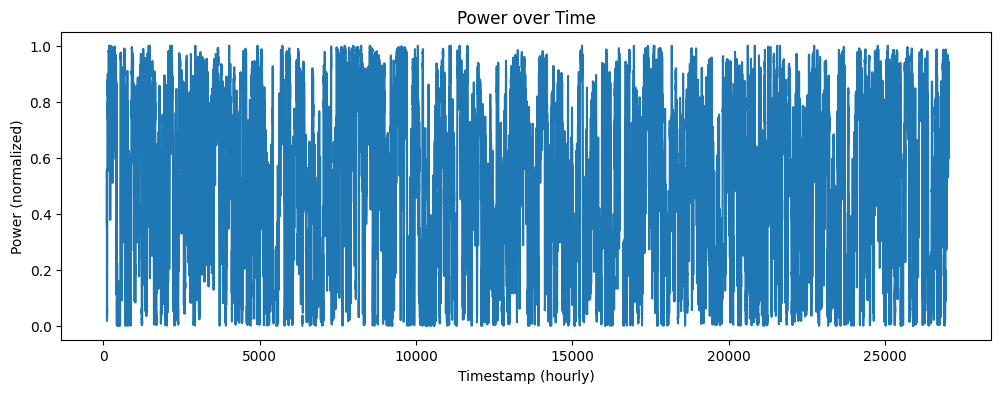

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4), linewidth=0.2, alpha=0.4)
wind['POWER'].plot(ax=ax)
ax.set_title('Power over Time')
ax.set_ylabel('Power (normalized)')
ax.set_xlabel('Timestamp (hourly)')
plt.show()

This doesn't help much to find a pattern. Plot where there are missing values instead. It does get clear though that power goes from 0-1 where 0 is (presumably) no power and 1 is full power.

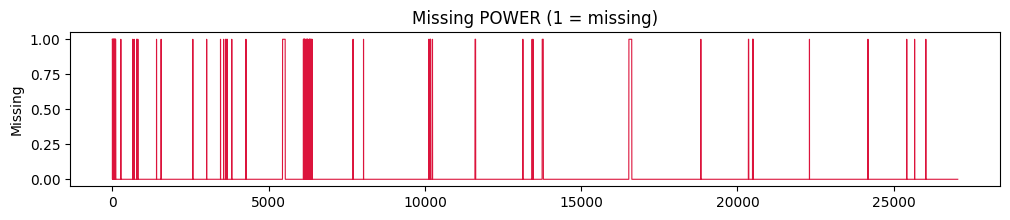

In [ ]:
wind['POWER'].isna().astype(int).plot(figsize=(12, 2), linewidth=0.8, color='crimson', title='Missing POWER (1 = missing)')
plt.ylabel('Missing')
plt.show()

There is no obvious pattern here. I believe it is safe to estimate these values. There are different approaches to this:<br> 
**Persistence fill:** whenever POWER is NaN, replace with previous valid value. <br>
**Moving-average fill:** to smooth noise, take average of last *m* hours. <br>
**Hourly climatology:** compute the mean power per hour-of-day over recent days; plug those values for missing values in the same time-stamp hour. <br>
<br>
Three versions of TrainData will be created, with the name 'wind_*method*'. The methods will be shorted with **persistance**, **average** and **hourly** for the three types of methods.

***Persistance fill***

In [ ]:
wind_persistance = wind.copy()
wind_persistance['POWER'] = wind_persistance['POWER'].ffill().bfill()
wind_persistance.head(10)

,TIMESTAMP,POWER,U10,V10,U100,V100
0,2015-01-01 01:00:00,0.666693,6.24102,3.49613,9.73707,4.78492
1,2015-01-01 02:00:00,0.666693,5.62234,4.06239,8.94497,5.71768
2,2015-01-01 03:00:00,0.666693,5.99531,4.89334,9.52143,6.99094
3,2015-01-01 04:00:00,0.666693,6.90809,4.79099,10.63280,6.75417
4,2015-01-01 05:00:00,0.666693,6.95268,4.83204,10.70080,6.74193
5,2015-01-01 06:00:00,0.937501,6.17865,5.70277,9.73491,8.09731
6,2015-01-01 07:00:00,0.937501,7.63436,4.76415,11.73130,6.60519
7,2015-01-01 08:00:00,0.937501,7.32686,5.98271,11.28840,8.46992
8,2015-01-01 09:00:00,0.935002,7.39201,5.66010,11.21580,8.10729
9,2015-01-01 10:00:00,0.935002,7.81017,5.22474,11.80900,7.32732


Looks like it has achieved what we wanted. Lets double check for any NaN values.

In [ ]:
wind_persistance['POWER'].isna().sum()

np.int64(0)

All rows have a non-NaN value.

***Moving-average fill***

In [ ]:
wind_average = wind.copy()

m = 5       ## MOVING AVERAGE OF THE M LAST HOURS, adjust this to balance models

rolling_mean = (
    wind_average['POWER']
    .rolling(window=m, min_periods=1)
    .mean()
)

wind_average['POWER'] = wind_average['POWER'].fillna(rolling_mean)
wind_average.head(20)

,TIMESTAMP,POWER,U10,V10,U100,V100
0,2015-01-01 01:00:00,NaN,6.24102,3.49613,9.73707,4.78492
1,2015-01-01 02:00:00,NaN,5.62234,4.06239,8.94497,5.71768
2,2015-01-01 03:00:00,0.666693,5.99531,4.89334,9.52143,6.99094
3,2015-01-01 04:00:00,0.666693,6.90809,4.79099,10.63280,6.75417
4,2015-01-01 05:00:00,0.666693,6.95268,4.83204,10.70080,6.74193
5,2015-01-01 06:00:00,0.937501,6.17865,5.70277,9.73491,8.09731
6,2015-01-01 07:00:00,0.802097,7.63436,4.76415,11.73130,6.60519
7,2015-01-01 08:00:00,0.937501,7.32686,5.98271,11.28840,8.46992
8,2015-01-01 09:00:00,0.935002,7.39201,5.66010,11.21580,8.10729
9,2015-01-01 10:00:00,0.936251,7.81017,5.22474,11.80900,7.32732


For row 0 and 1 we are missing values due to there being no first point to linearize with. Lets check if there are more missing values:

In [ ]:
wind_average['POWER'].isna().sum()

np.int64(248)

This will differ depending on the value of *m*, but with m = 5 POWER is missing 248 values. We will take care of these by filling in with the functions ffill() and bfill(). <br>
bfill() handles the opening gap by copying the first valid value backward; ffill() then catches anything in between.

In [ ]:
wind_average['POWER'] = wind_average['POWER'].ffill().bfill()
wind_average.head()

,TIMESTAMP,POWER,U10,V10,U100,V100
0,2015-01-01 01:00:00,0.666693,6.24102,3.49613,9.73707,4.78492
1,2015-01-01 02:00:00,0.666693,5.62234,4.06239,8.94497,5.71768
2,2015-01-01 03:00:00,0.666693,5.99531,4.89334,9.52143,6.99094
3,2015-01-01 04:00:00,0.666693,6.90809,4.79099,10.63280,6.75417
4,2015-01-01 05:00:00,0.666693,6.95268,4.83204,10.70080,6.74193


In [ ]:
wind_average['POWER'].isna().sum()

np.int64(0)

Now there are no NaN values.

***Hourly climatology***

In [ ]:
wind_hourly = wind.copy()
hourly_means = wind_hourly.groupby(wind_hourly['TIMESTAMP'].dt.hour)['POWER'].mean()
hourly_means    # Series with mean POWER for each hour of the day

TIMESTAMP
0     0.514555
1     0.509696
2     0.505619
3     0.511900
4     0.503110
5     0.507338
6     0.514493
7     0.515249
8     0.518379
9     0.529944
10    0.531480
11    0.537485
12    0.544924
13    0.544830
14    0.540171
15    0.537040
16    0.524717
17    0.520302
18    0.515628
19    0.510324
20    0.504638
21    0.508554
22    0.508014
23    0.513489
Name: POWER, dtype: float64

In [ ]:
wind_hourly['POWER'] = wind_hourly['POWER'].fillna(hourly_means).ffill().bfill()
wind_hourly.head(10)

,TIMESTAMP,POWER,U10,V10,U100,V100
0,2015-01-01 01:00:00,0.514555,6.24102,3.49613,9.73707,4.78492
1,2015-01-01 02:00:00,0.509696,5.62234,4.06239,8.94497,5.71768
2,2015-01-01 03:00:00,0.666693,5.99531,4.89334,9.52143,6.99094
3,2015-01-01 04:00:00,0.511900,6.90809,4.79099,10.63280,6.75417
4,2015-01-01 05:00:00,0.503110,6.95268,4.83204,10.70080,6.74193
5,2015-01-01 06:00:00,0.937501,6.17865,5.70277,9.73491,8.09731
6,2015-01-01 07:00:00,0.514493,7.63436,4.76415,11.73130,6.60519
7,2015-01-01 08:00:00,0.515249,7.32686,5.98271,11.28840,8.46992
8,2015-01-01 09:00:00,0.935002,7.39201,5.66010,11.21580,8.10729
9,2015-01-01 10:00:00,0.529944,7.81017,5.22474,11.80900,7.32732


We can manually see that the previous empty rows now contain their hourly average seen in the hourly_means series above. Lets check for any NaN values.

In [ ]:
wind_hourly['POWER'].isna().sum()

np.int64(0)

Also 0, great!

**Polar coordinates**

As stated before, it could be helpful to convert the vectors **u** and **v** into the polar coordinate equivilent. With that information we can make graphs that plot, for example, magnitude (wind speed) against time on different time-scales. With this we can try to make out patterns manually before giving the data to models.

**Define a function** that converts to polar

In [ ]:
def convert_to_polar(wind, u, v, prefix):
    wind[f'{prefix}_speed'] = np.sqrt(wind[u]**2 + wind[v]**2)          ##length of hypotenuse, magnitude
    wind[f'{prefix}_direction'] = np.arctan2(wind[v], wind[u]) * (180 / np.pi)
    wind[f'{prefix}_direction'] = (wind[f'{prefix}_direction'] + 360) % 360
    return wind

Apply it to wind_persistance and create a new copy with the polar coordinates.

In [ ]:
wind_persistance_polar = convert_to_polar(wind_persistance, 'U10', 'V10', 'wind_10m')
wind_persistance_polar = convert_to_polar(wind_persistance_polar, 'U100', 'V100', 'wind_100m')
wind_persistance_polar = wind_persistance_polar.drop(columns=['U10', 'V10', 'U100', 'V100'])
wind_persistance_polar.head(10)

,TIMESTAMP,POWER,wind_10m_speed,wind_10m_direction,wind_100m_speed,wind_100m_direction
0,2015-01-01 01:00:00,0.666693,7.153548,29.256924,10.849239,26.170089
1,2015-01-01 02:00:00,0.666693,6.936405,35.849781,10.616231,32.586965
2,2015-01-01 03:00:00,0.666693,7.738767,39.221140,11.812319,36.287312
3,2015-01-01 04:00:00,0.666693,8.406860,34.742594,12.596636,32.424540
4,2015-01-01 05:00:00,0.666693,8.466898,34.798897,12.647559,32.212561


Repeat for wind_average and wind_hourly

In [ ]:
wind_average_polar = convert_to_polar(wind_average, 'U10', 'V10', 'wind_10m')
wind_average_polar = convert_to_polar(wind_average_polar, 'U100', 'V100', 'wind_100m')
wind_average_polar = wind_average_polar.drop(columns=['U10', 'V10', 'U100', 'V100'])
wind_average_polar.head(10)

,TIMESTAMP,POWER,wind_10m_speed,wind_10m_direction,wind_100m_speed,wind_100m_direction
0,2015-01-01 01:00:00,0.666693,7.153548,29.256924,10.849239,26.170089
1,2015-01-01 02:00:00,0.666693,6.936405,35.849781,10.616231,32.586965
2,2015-01-01 03:00:00,0.666693,7.738767,39.221140,11.812319,36.287312
3,2015-01-01 04:00:00,0.666693,8.406860,34.742594,12.596636,32.424540
4,2015-01-01 05:00:00,0.666693,8.466898,34.798897,12.647559,32.212561


In [ ]:
wind_hourly_polar = convert_to_polar(wind_hourly, 'U10', 'V10', 'wind_10m')
wind_hourly_polar = convert_to_polar(wind_hourly_polar, 'U100', 'V100', 'wind_100m')
wind_hourly_polar = wind_hourly_polar.drop(columns=['U10', 'V10', 'U100', 'V100'])
wind_hourly_polar.head(10)

,TIMESTAMP,POWER,wind_10m_speed,wind_10m_direction,wind_100m_speed,wind_100m_direction
0,2015-01-01 01:00:00,0.514555,7.153548,29.256924,10.849239,26.170089
1,2015-01-01 02:00:00,0.509696,6.936405,35.849781,10.616231,32.586965
2,2015-01-01 03:00:00,0.666693,7.738767,39.221140,11.812319,36.287312
3,2015-01-01 04:00:00,0.511900,8.406860,34.742594,12.596636,32.424540
4,2015-01-01 05:00:00,0.503110,8.466898,34.798897,12.647559,32.212561


## Summary
From the file TrainData_A I have created 6 different copies.<br>
3 of these are vector based and use 3 different fill functions for the missing POWER values. <br>
The remaining 3 are the polar coordinate equivalent in order to explore the data visually.